In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv(r"C:\Users\Admin\Downloads\student_tea_snacks _1_.csv")

In [8]:
df

,student_id,gender,age_group,prefers_tea,tea_type,snack_choice,cups_per_day
0,S001,Male,21-23,No,Black,Samosa,2
1,S002,Male,21-23,No,Green,Samosa,3
2,S003,Male,18-20,No,Doodh Patti,Biscuit,0
3,S004,Male,21-23,Yes,NaN,Samosa,1
4,S005,Male,18-20,Yes,Green,Samosa,4
...,...,...,...,...,...,...,...
95,S096,Male,18-20,Yes,NaN,Biscuit,4
96,S097,Female,18-20,No,Doodh Patti,Biscuit,3
97,S098,Female,18-20,Yes,NaN,Chips,2
98,S099,Female,21-23,Yes,Black,Chips,4


In [3]:
print(df.to_string())

   student_id  gender age_group prefers_tea     tea_type snack_choice  cups_per_day
0        S001    Male     21-23          No        Black       Samosa             2
1        S002    Male     21-23          No        Green       Samosa             3
2        S003    Male     18-20          No  Doodh Patti      Biscuit             0
3        S004    Male     21-23         Yes          NaN       Samosa             1
4        S005    Male     18-20         Yes        Green       Samosa             4
5        S006  Female     18-20         Yes        Black        Chips             5
6        S007    Male     24-26          No        Green        Chips             4
7        S008    Male     18-20         Yes        Black        Chips             2
8        S009  Female     18-20          No        Green      Biscuit             4
9        S010  Female     21-23         Yes          NaN       Samosa             5
10       S011  Female     21-23          No          NaN        Chips       

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   student_id    100 non-null    str  
 1   gender        100 non-null    str  
 2   age_group     100 non-null    str  
 3   prefers_tea   100 non-null    str  
 4   tea_type      77 non-null     str  
 5   snack_choice  100 non-null    str  
 6   cups_per_day  100 non-null    int64
dtypes: int64(1), str(6)
memory usage: 5.6 KB


In [7]:
df.describe()

,cups_per_day
count,100.000000
mean,2.810000
std,1.673893
min,0.000000
25%,1.750000
50%,3.000000
75%,4.000000
max,5.000000


In [11]:
df.isna().sum()

student_id       0
gender           0
age_group        0
prefers_tea      0
tea_type        23
snack_choice     0
cups_per_day     0
dtype: int64

In [22]:
df.groupby('tea_type').count()


,student_id,gender,age_group,prefers_tea,snack_choice,cups_per_day
tea_type,,,,,,
Black,23,23,23,23,23,23
Doodh Patti,25,25,25,25,25,25
Green,29,29,29,29,29,29


# Green is the most preferred tep type

In [24]:
avg_no_of_cups = df.groupby('tea_type')['cups_per_day'].mean()
print(f"Average number of cups per day for each tea type:\n{avg_no_of_cups}")

Average number of cups per day for each tea type:
tea_type
Black          3.000000
Doodh Patti    3.000000
Green          2.689655
Name: cups_per_day, dtype: float64


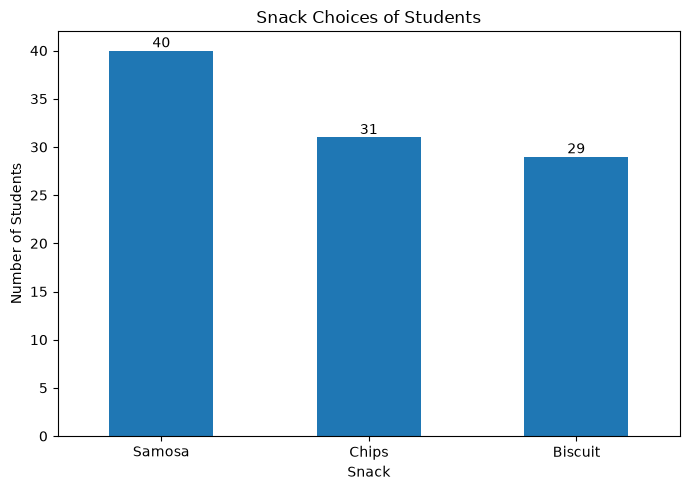

In [28]:
snack_counts = df["snack_choice"].value_counts()
ax = snack_counts.plot(kind="bar", figsize=(7, 5))
plt.title("Snack Choices of Students")
plt.xlabel("Snack"); plt.ylabel("Number of Students")
plt.xticks(rotation=0)
for c in ax.containers:
    ax.bar_label(c)
plt.tight_layout()
plt.savefig("snack_choices_bar_chart.png", dpi=150)
plt.show()

In [30]:
tea_by_age = pd.crosstab(df["age_group"], df["prefers_tea"])
print(tea_by_age)

prefers_tea  No  Yes
age_group           
18-20        19   20
21-23        17   15
24-26        13   16


prefers_tea    No   Yes
age_group              
18-20        48.7  51.3
21-23        53.1  46.9
24-26        44.8  55.2


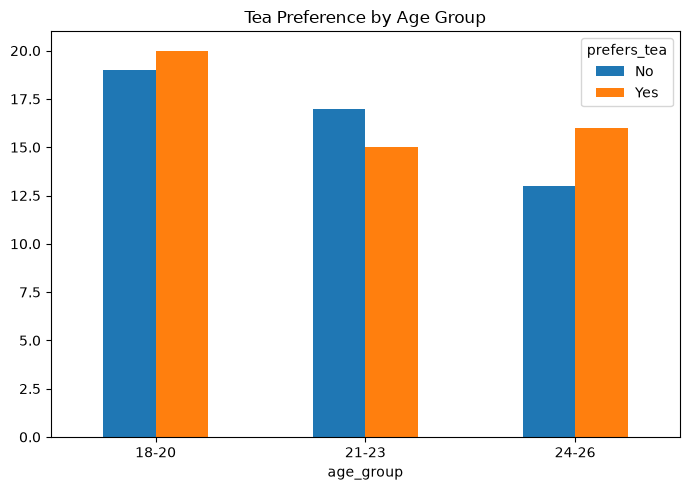

In [31]:
print((pd.crosstab(df["age_group"], df["prefers_tea"], normalize="index") * 100).round(1))
tea_by_age.plot(kind="bar", figsize=(7, 5))
plt.title("Tea Preference by Age Group")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [33]:
print("Number of students who don't prefer tea:", (df["prefers_tea"] == "No").sum())

Number of students who don't prefer tea: 49
